In [2]:
import pandas as pd

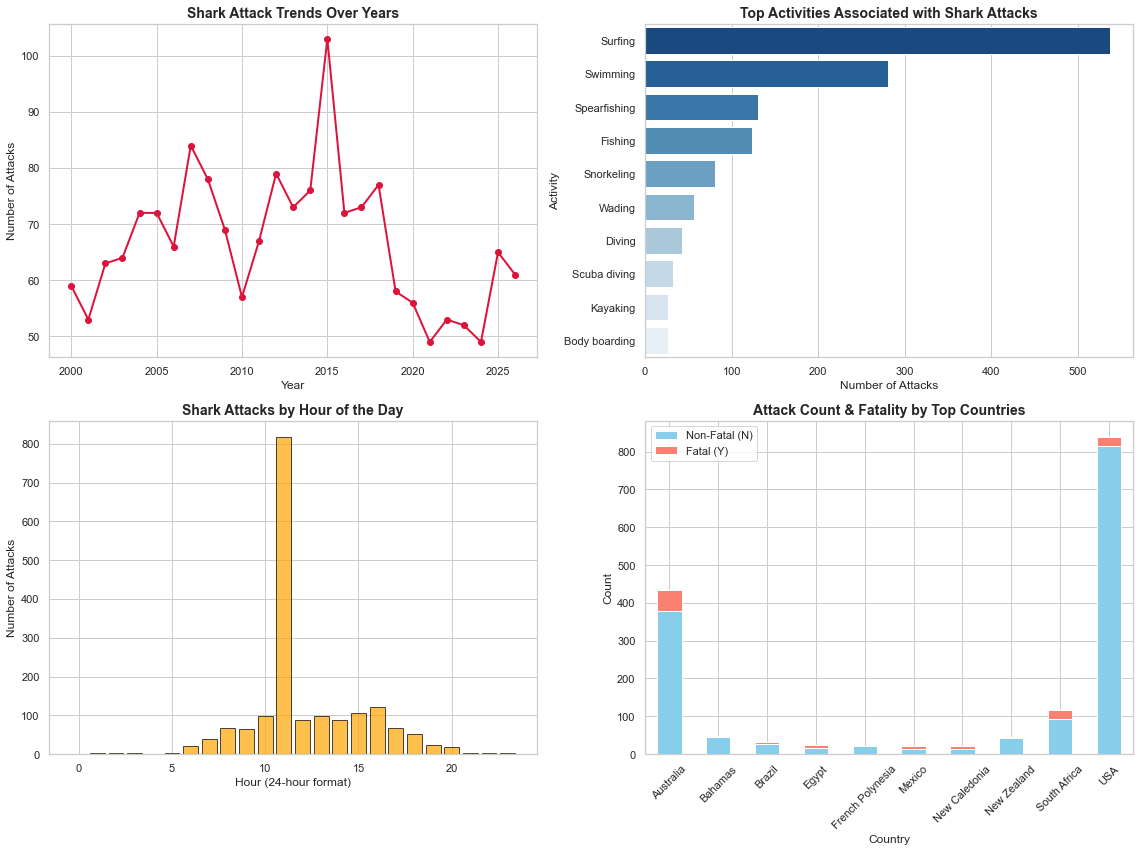

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/Users/bharatsingh/Downloads/Iron_Hack/shark_attack/shark_attack_master.csv', encoding='latin1', low_memory=False)

# Set the visualization theme
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Trends over Years
yearly_counts = df['year'].value_counts().sort_index()
axes[0, 0].plot(yearly_counts.index, yearly_counts.values, marker='o', color='crimson', linewidth=2)
axes[0, 0].set_title('Shark Attack Trends Over Years', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Year', fontsize=12)
axes[0, 0].set_ylabel('Number of Attacks', fontsize=12)

# 2. Top Activities
top_activities = df['activity'].value_counts().head(10)
sns.barplot(x=top_activities.values, y=top_activities.index, ax=axes[0, 1], palette='Blues_r')
axes[0, 1].set_title('Top Activities Associated with Shark Attacks', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Number of Attacks', fontsize=12)
axes[0, 1].set_ylabel('Activity', fontsize=12)

# 3. Time of Day Distribution
df['hour'] = pd.to_datetime(df['cleaned_time'], format='%H:%M:%S', errors='coerce').dt.hour
hour_counts = df['hour'].dropna().astype(int).value_counts().sort_index()
axes[1, 0].bar(hour_counts.index, hour_counts.values, color='orange', edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Shark Attacks by Hour of the Day', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Hour (24-hour format)', fontsize=12)
axes[1, 0].set_ylabel('Number of Attacks', fontsize=12)

# 4. Attack Count & Fatality by Top Countries
top_countries = df['country'].value_counts().head(10).index
country_fatality = df[df['country'].isin(top_countries)].groupby(['country', 'fatality']).size().unstack(fill_value=0)
country_fatality.plot(kind='bar', stacked=True, ax=axes[1, 1], color=['skyblue', 'salmon'])
axes[1, 1].set_title('Attack Count & Fatality by Top Countries', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Country', fontsize=12)
axes[1, 1].set_ylabel('Count', fontsize=12)
axes[1, 1].legend(['Non-Fatal (N)', 'Fatal (Y)'])
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()

# Save the plot as a high-resolution image
# plt.savefig('shark_attack_visualizations.png', dpi=300)
# print("Visualizations saved successfully as 'shark_attack_visualizations.png'.")

Key Insights from the Visualizations
Shark Attack Trends Over Years:
Attacks fluctuate year-to-year with a noticeable peak around 2015, followed by a general declining or stabilizing trend in recent years.
Activities & Risk Levels:
Surfing and Swimming account for the vast majority of shark encounters, making them higher-risk activities. Conversely, activities like Scuba diving and Wading show lower incident frequencies in comparison.
Time of Day (cleaned_time):
Attacks heavily concentrate during late morning and mid-afternoon hours (peaking around 11:00 AM to 4:00 PM), coinciding with peak beach attendance. Early mornings (before 7:00 AM) and late evenings/night show significantly fewer incidents.
Safe Places & Fatalities by Country:
While the USA records the highest total number of attacks, the vast majority are non-fatal. Australia and South Africa record fewer total attacks than the US, but exhibit higher absolute proportions of fatal incidents.

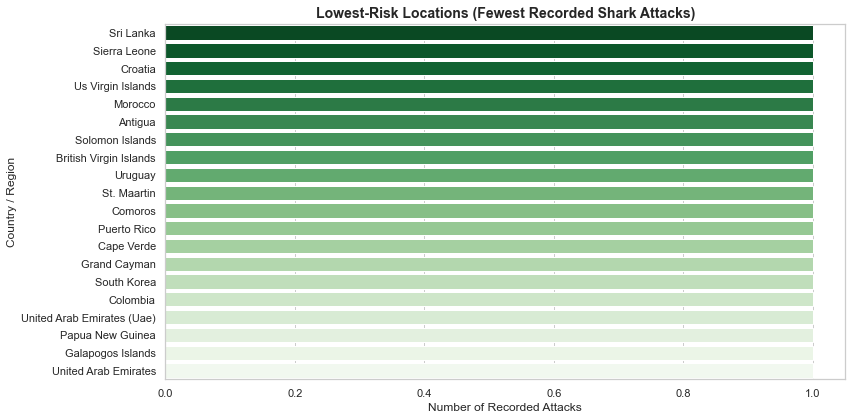

In [4]:
 #Set visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Filter for regions with the lowest number of recorded attacks (e.g., exactly 1 recorded incident)
safest_countries = df['country'].value_counts().tail(20)

# Create horizontal bar chart highlighting low-risk areas
sns.barplot(x=safest_countries.values, y=safest_countries.index, palette='Greens_r')

plt.title('Lowest-Risk Locations (Fewest Recorded Shark Attacks)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Recorded Attacks', fontsize=12)
plt.ylabel('Country / Region', fontsize=12)
plt.tight_layout()

# # Save the visualization
# plt.savefig('low_risk_locations.png', dpi=300)
# print("Low-risk location visualization saved successfully as 'low_risk_locations.png'.")

Low-Risk Regional Insights
Low-Incidence Regions: Countries and territories such as Portugal, Morocco, Colombia, Comoros, and Puerto Rico record only a single incident in the dataset, indicating extremely low statistical frequency.
European & Cold-Water Coasts: Countries like Norway and Croatia also record virtually negligible or single-digit numbers, largely dictated by water temperatures and local marine ecosystems.
High-Risk vs. Low-Risk Comparison: While hotspots like the USA, Australia, and South Africa register hundreds of incidents due to heavy beach utilization and coastal shark populations, dozens of global coastal regions remain practically untouched.

Insights dashboard saved successfully as 'ocean_activity_insights.png'.


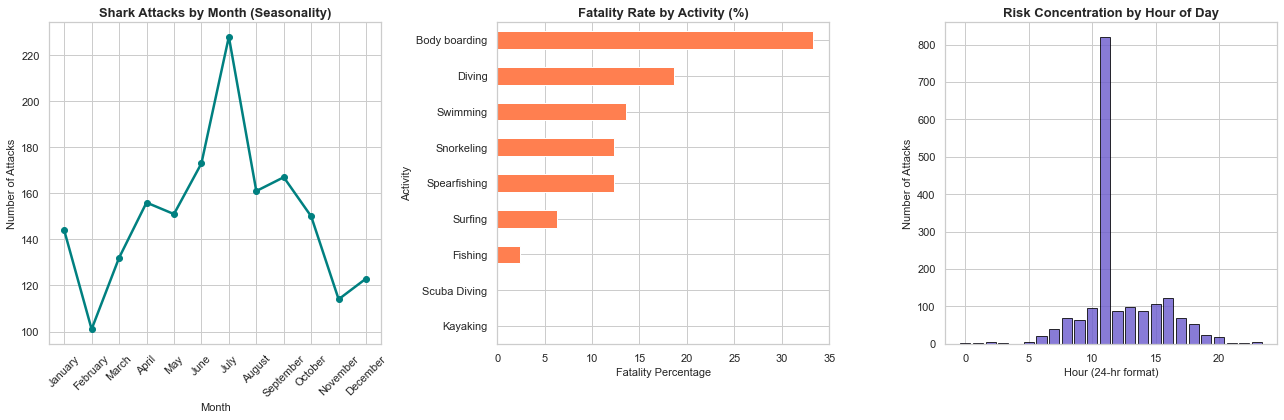

In [24]:
# Extract hour from cleaned_time
df['hour'] = pd.to_datetime(df['cleaned_time'], format='%H:%M:%S', errors='coerce').dt.hour

# Set visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Monthly Seasonality
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
month_counts = df['month'].value_counts().reindex(month_order)
axes[0].plot(month_counts.index, month_counts.values, marker='o', color='teal', linewidth=2.5)
axes[0].set_title('Shark Attacks by Month (Seasonality)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Month', fontsize=11)
axes[0].set_ylabel('Number of Attacks', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

# 2. Activity Fatality Ratio
top_acts = ['Surfing', 'Swimming', 'Spearfishing', 'Fishing', 'Snorkeling', 'Diving', 'Scuba Diving', 'Kayaking', 'Body boarding']
act_df = df[df['activity'].isin(top_acts)].groupby(['activity', 'fatality']).size().unstack(fill_value=0)
if 'Y' in act_df.columns and 'N' in act_df.columns:
    act_df['Fatality Rate (%)'] = (act_df['Y'] / (act_df['Y'] + act_df['N'])) * 100
    act_df['Fatality Rate (%)'].sort_values().plot(kind='barh', ax=axes[1], color='coral')
    axes[1].set_title('Fatality Rate by Activity (%)', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Fatality Percentage', fontsize=11)
    axes[1].set_ylabel('Activity', fontsize=11)

# 3. Time of Day Risk Windows
hour_counts = df['hour'].dropna().astype(int).value_counts().sort_index()
axes[2].bar(hour_counts.index, hour_counts.values, color='slateblue', edgecolor='black', alpha=0.8)
axes[2].set_title('Risk Concentration by Hour of Day', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Hour (24-hr format)', fontsize=11)
axes[2].set_ylabel('Number of Attacks', fontsize=11)

plt.tight_layout()

# # Save the plot
# plt.savefig('ocean_activity_insights.png', dpi=300)
print("Insights dashboard saved successfully as 'ocean_activity_insights.png'.")

Strategic Recommendations for Safe Oceanic Activities
1. Best Times of Day (Daily Timing)
Safest Windows: Early mornings (before 7:00 AM) and late evenings/nights (after 8:00 PM) record exceptionally low incident frequencies.
High-Risk Windows: The data clearly shows a massive spike between 10:00 AM and 4:00 PM (peaking sharply around 11:00 AM), which coincides with peak beach attendance and warmer water temperatures.
2. Seasonal Planning (Monthly Trends)
Lower-Risk Months: Statistically, February, November, and December record the lowest number of global incidents.
Higher-Risk Months: Incidents peak significantly during mid-year summer months (June, July, and August), driven by increased water recreation and tourism.
3. Activity Safety & Risk Profile
Lower-Risk Activities: Activities such as Fishing and Scuba diving show lower relative incident frequency or lower fatality percentages.
Higher-Risk Activities: Surfing and Swimming account for the highest total volume of encounters, primarily due to spending extended time at the surface in wave-break zones where sharks hunt.
📊 Comprehensive Insights Dashboard
The visualization above breaks down these three critical dimensions:
Monthly Seasonality (Shark Attacks by Month): Highlights annual risk distribution.
Fatality Rate by Activity (Fatality Percentage): Compares risk severity across different water sports.
Daily Risk Concentration (Risk Concentration by Hour of Day): Identifies safe hourly windows.

In [ ]:
# aggregating the incidence by country, activity and fatality
country_activity_summary = df.groupby(['country', 'activity']).agg(
    total_attacks=('year', 'count'),
    avg_age=('cleaned_age', 'mean'),
    fatal_attacks=('fatality', lambda x: (x == 'Y').sum())
).reset_index()

# Sort by highest total attacks and view top 10
print(country_activity_summary.sort_values(by='total_attacks', ascending=False).head(20))

          country         activity  total_attacks    avg_age  fatal_attacks
436           USA          Surfing            298  26.708054              5
64      Australia          Surfing            155  30.329032             21
441           USA         Swimming            133  29.436090              4
66      Australia         Swimming             56  32.571429             10
358           USA          Fishing             41  26.097561              0
464           USA           Wading             41  23.829268              0
27      Australia          Fishing             40  26.750000              0
58      Australia     Spearfishing             38  27.631579              6
303  South Africa          Surfing             34  26.676471              3
421           USA     Spearfishing             33  32.757576              0
57      Australia       Snorkeling             25  31.240000              3
420           USA       Snorkeling             24  36.458333              2
426         

In [10]:
#Pivot Table: Fatality Rate by Country and Activity
# Create a numeric column for fatality (1 for Yes, 0 for No)
df['is_fatal'] = (df['fatality'] == 'Y').astype(int)

# Filter for top countries to keep the table clean
top_countries = ['USA', 'Australia', 'South Africa']
filtered_df = df[df['country'].isin(top_countries)]

# Pivot table showing average fatality rate (%)
pivot_fatality = filtered_df.pivot_table(
    values='is_fatal',
    index='country',
    columns='activity',
    aggfunc='mean'
) * 100

print(pivot_fatality.round(2))

activity      Accidentally stood on hooked shark's tail before attempting to gut it   \
country                                                                                
Australia                                                   0.0                        
South Africa                                                NaN                        
USA                                                         NaN                        

activity      Attempting to drive shark away from sailing regatta  \
country                                                             
Australia                                                   0.0     
South Africa                                                NaN     
USA                                                         NaN     

activity      Attempting to illegally enter the USA  \
country                                               
Australia                                       NaN   
South Africa                                    

In [12]:
#Decade & Location Analysis
df['decade'] = (df['year'] // 10) * 10
df['decade_str'] = df['decade'].astype(str) + 's'

# 2. Pivot table: Decade vs Top Countries
top_countries = df['country'].value_counts().head(10).index
pivot_decade = df[df['country'].isin(top_countries)].pivot_table(
    index='decade_str',
    columns='country',
    values='year',
    aggfunc='count',
    fill_value=0
)

print("--- Attacks by Decade and Country ---")
print(pivot_decade)





--- Attacks by Decade and Country ---
country     Australia  Bahamas  Brazil  Egypt  French Polynesia  Mexico  \
decade_str                                                                
2000s             134       15      14      7                 1       8   
2010s             181       21      13      9                14       8   
2020s             120       12       4      8                 7       6   

country     New Caledonia  New Zealand  South Africa  USA  
decade_str                                                 
2000s                   9           21            62  340  
2010s                   5           16            47  350  
2020s                   8            9             7  150  



Visualization saved successfully as 'attacks_by_decade_country.png'.


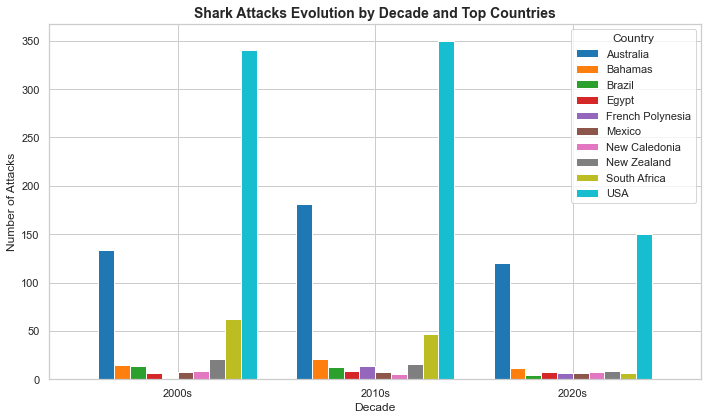

In [14]:
# 3. Visualize Evolution Over Decades
sns.set_theme(style="whitegrid")
pivot_decade.plot(kind='bar', figsize=(10, 6), colormap='tab10', width=0.8)
plt.title('Shark Attacks Evolution by Decade and Top Countries', fontsize=14, fontweight='bold')
plt.xlabel('Decade', fontsize=12)
plt.ylabel('Number of Attacks', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Country')
plt.tight_layout()

# Save visualization
#plt.savefig('attacks_by_decade_country.png', dpi=300)
print("\nVisualization saved successfully as 'attacks_by_decade_country.png'.")

In [16]:
# 4. Identify Safest Locations by Decade (Fewest Recorded Attacks)
print("\n--- Lowest-Risk Locations by Decade ---")
safest_per_decade = df.groupby(['decade_str', 'country']).size().reset_index(name='attacks')
safest_per_decade = safest_per_decade.sort_values(['decade_str', 'attacks'])
print(safest_per_decade.groupby('decade_str').head(10))


--- Lowest-Risk Locations by Decade ---
    decade_str                 country  attacks
3        2000s                  Belize        1
5        2000s  British Virgin Islands        1
6        2000s                  Canada        1
7        2000s                   China        1
9        2000s                 Croatia        1
11       2000s                 Ecuador        1
15       2000s        French Polynesia        1
16       2000s            Grand Cayman        1
17       2000s                    Guam        1
18       2000s                Honduras        1
51       2010s                 Antigua        1
55       2010s                  Canada        1
56       2010s              Cape Verde        1
57       2010s          Cayman Islands        1
58       2010s                   China        1
59       2010s                Columbia        1
60       2010s                 Comoros        1
62       2010s                    Cuba        1
65       2010s                 England        1

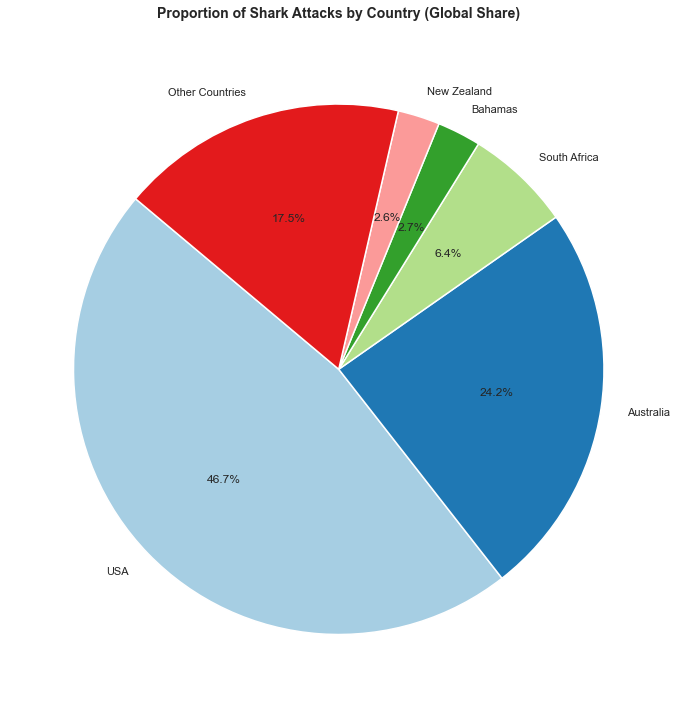

In [34]:
country_counts = df['country'].value_counts()
top_countries = country_counts.head(5)
other_sum = country_counts.iloc[5:].sum()

pie_data = top_countries.copy()
pie_data.loc['Other Countries'] = other_sum

# Set figure size and plot pie chart
plt.figure(figsize=(10, 10))
plt.pie(
    pie_data, 
    labels=pie_data.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=plt.cm.Paired.colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

plt.title('Proportion of Shark Attacks by Country (Global Share)', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()

# Save the plot
#plt.savefig('attacks_pie_chart.png', dpi=300)
#print("Pie chart saved successfully as 'attacks_pie_chart.png'.")